In [128]:
import pandas as pd
import numpy as np

In [129]:
df = pd.read_csv("approval_dataset.csv")
df

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996.0,NaN,9092.0,Salaried,58.0,Married,0.0,557.0,0.0,0.59,5370.0,43563.0,8311.0,72.0,Personal,NaN,Not Graduate,Male,Unemployed,No
996,997.0,3279.0,6356.0,Self-employed,58.0,Married,1.0,646.0,3.0,0.19,NaN,18361.0,22563.0,12.0,Business,Urban,Graduate,Female,Government,No
997,998.0,15192.0,8433.0,Contract,48.0,Single,1.0,666.0,1.0,0.40,8581.0,41335.0,16203.0,24.0,Home,Rural,Graduate,Male,MNC,No
998,999.0,9083.0,7380.0,Unemployed,50.0,Single,1.0,748.0,3.0,0.31,13491.0,8933.0,10290.0,36.0,Personal,Urban,Graduate,Male,Private,Yes


In [130]:
print(df.info())
print(df.describe())
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [131]:
cat_cols = df.select_dtypes(include='object').columns
num_cols = df.select_dtypes(include='float64').columns

### Handling Missing Values:

In [132]:
from sklearn.impute import SimpleImputer
num_imputer = SimpleImputer(strategy="mean")
cat_imputer = SimpleImputer(strategy="most_frequent")

In [133]:
df[num_cols] = num_imputer.fit_transform(df[num_cols])
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

### Exploratory Data Analysis

In [134]:
import seaborn as sns
import matplotlib.pyplot as plt
# because of classification problem, we should check that if our target classes are balanced
count = df['Loan_Approved'].value_counts()
count

Loan_Approved
No     702
Yes    298
Name: count, dtype: int64

Text(0.5, 1.0, 'Is Loan Approved?')

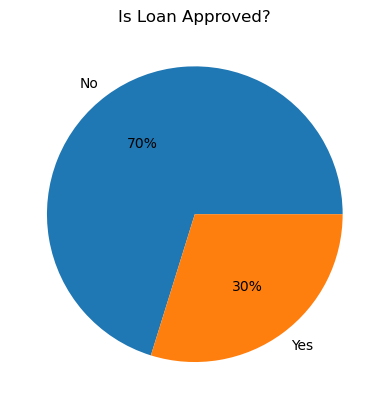

In [135]:
plt.pie(count,labels=['No','Yes'],autopct='%1.0f%%')
plt.title("Is Loan Approved?")


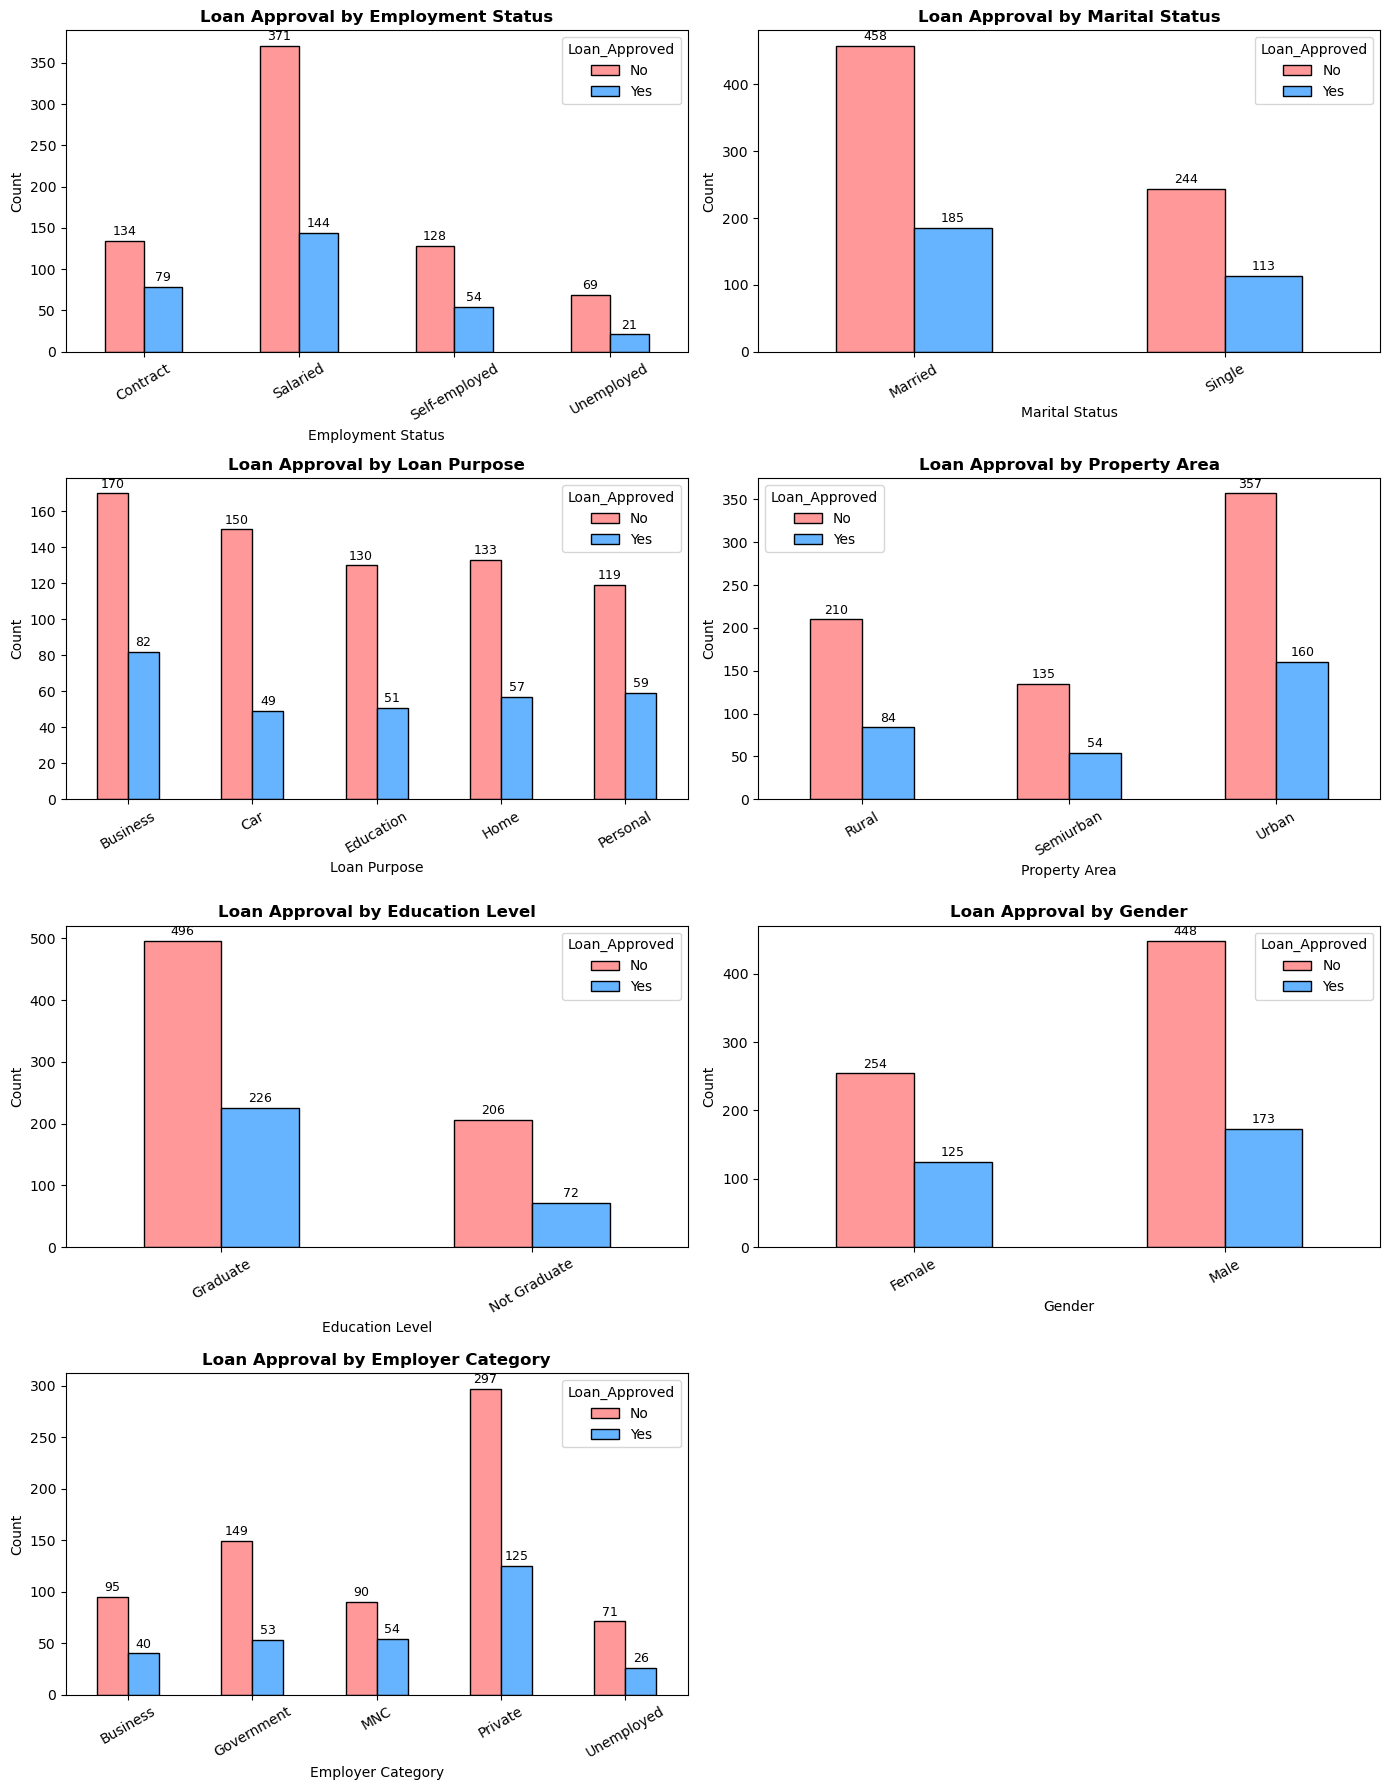

In [136]:
categorical_cols = [
    'Employment_Status', 'Marital_Status', 'Loan_Purpose', 
    'Property_Area', 'Education_Level', 'Gender', 'Employer_Category'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

axes = axes.flatten()

bar_colors = ['#ff9999', '#66b3ff']

for i, col in enumerate(categorical_cols):
    ax = axes[i]
    
    df.groupby([col, 'Loan_Approved']).size().unstack().plot(
        kind='bar', color=bar_colors, ax=ax, edgecolor='black'
    )
    
    # Customizations
    ax.set_title(f'Loan Approval by {col.replace("_", " ")}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col.replace("_", " "))
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)  
    
    for container in ax.containers:
        ax.bar_label(container, padding=2, fontsize=9)

axes[-1].axis('off')

plt.tight_layout()
plt.show()


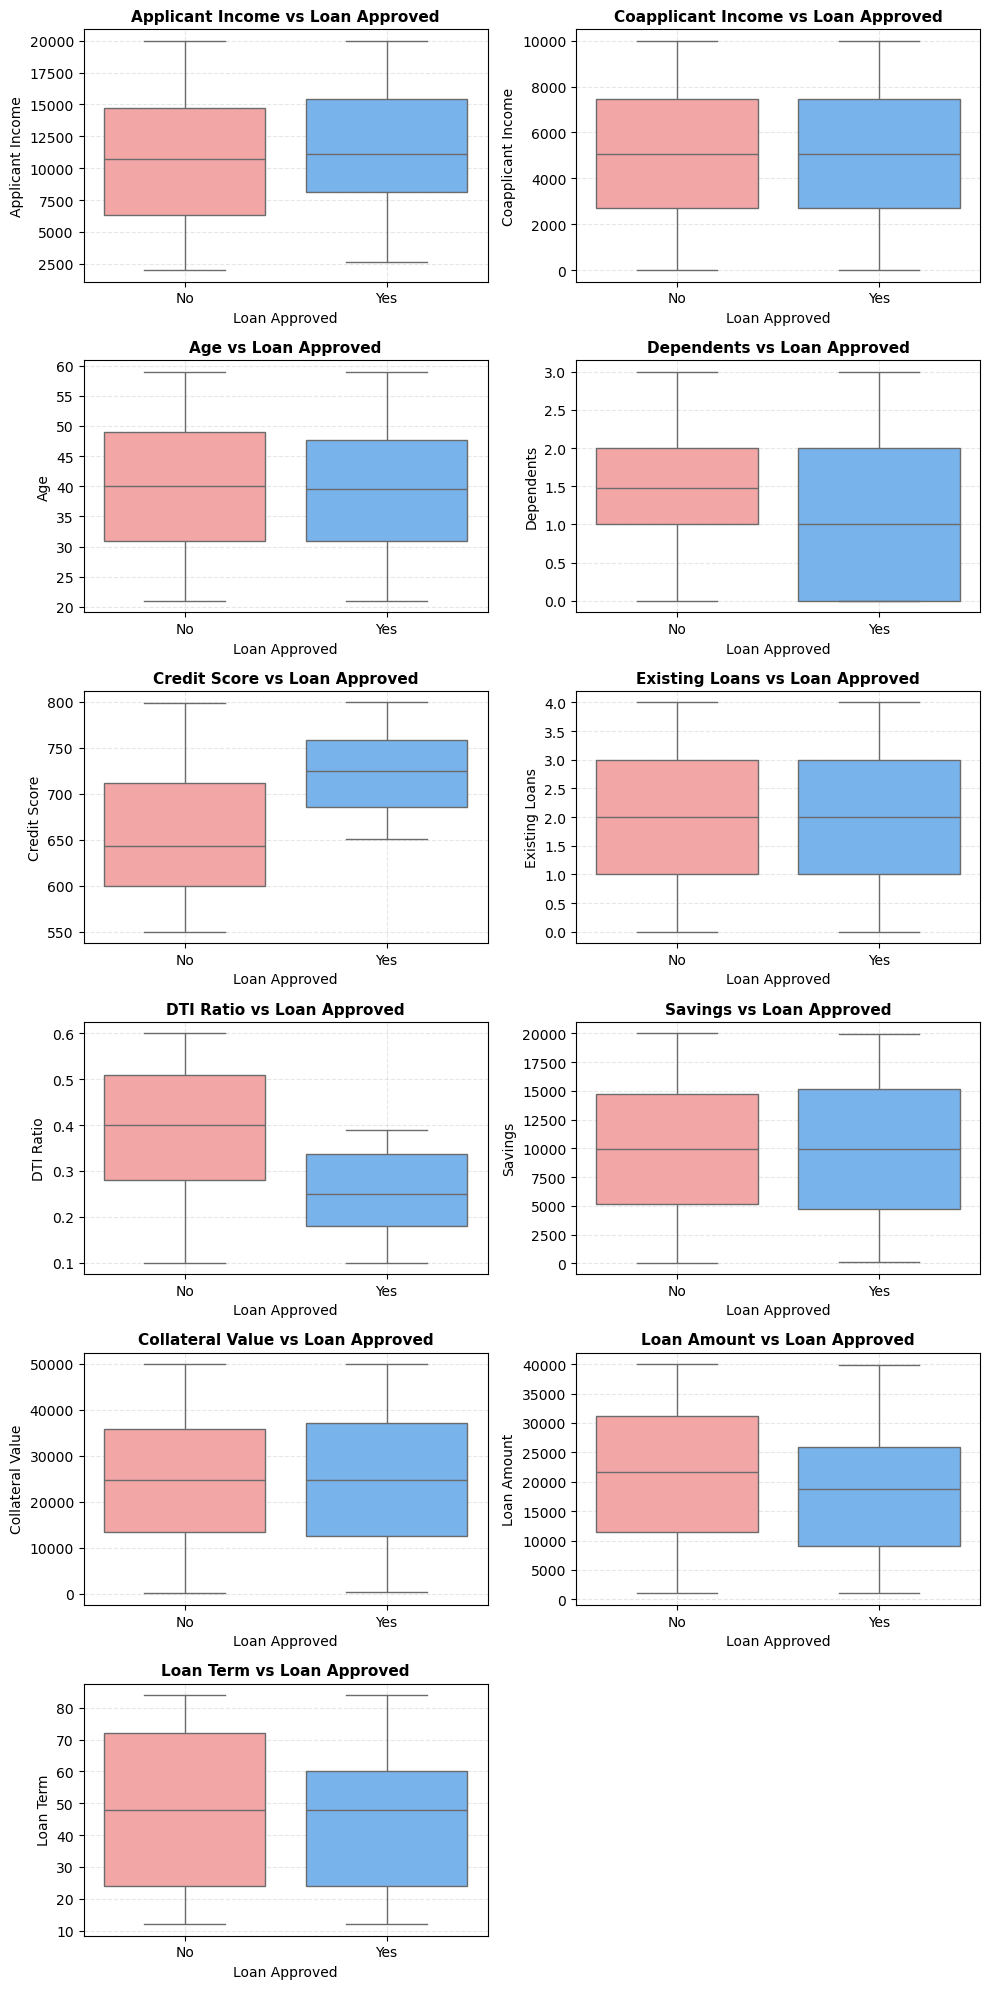

In [137]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Numerical columns ki list (Applicant_ID ke baghair)
numerical_cols = [
    'Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 
    'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 
    'Collateral_Value', 'Loan_Amount', 'Loan_Term'
]

fig, axes = plt.subplots(6, 2, figsize=(10, 20))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    ax = axes[i]
    
    sns.boxplot(
        data=df, 
        x='Loan_Approved', 
        y=col, 
        ax=ax, 
        palette=['#ff9999', '#66b3ff'], 
        hue='Loan_Approved', 
        legend=False
    )
    
    # Customizations
    ax.set_title(f'{col.replace("_", " ")} vs Loan Approved', fontsize=11, fontweight='bold')
    ax.set_xlabel('Loan Approved')
    ax.set_ylabel(col.replace("_", " "))
    ax.grid(True, linestyle='--', alpha=0.3)

axes[-1].axis('off')

plt.tight_layout()
plt.show()


### Encoding.

In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        1000 non-null   float64
 1   Applicant_Income    1000 non-null   float64
 2   Coapplicant_Income  1000 non-null   float64
 3   Employment_Status   1000 non-null   object 
 4   Age                 1000 non-null   float64
 5   Marital_Status      1000 non-null   object 
 6   Dependents          1000 non-null   float64
 7   Credit_Score        1000 non-null   float64
 8   Existing_Loans      1000 non-null   float64
 9   DTI_Ratio           1000 non-null   float64
 10  Savings             1000 non-null   float64
 11  Collateral_Value    1000 non-null   float64
 12  Loan_Amount         1000 non-null   float64
 13  Loan_Term           1000 non-null   float64
 14  Loan_Purpose        1000 non-null   object 
 15  Property_Area       1000 non-null   object 
 16  Educati

In [139]:
from sklearn.preprocessing import  OneHotEncoder,LabelEncoder
le = LabelEncoder()
df['Loan_Approved'] =  le.fit_transform(df['Loan_Approved'])


df['Education_Level'] = df['Education_Level'].map({'Not Graduate': 0, 'Graduate': 1})
df['Employment_Status'] = df['Employment_Status'].map({'Unemployed': 0, 'Contract': 1,'Salaried': 2,'Self-employed':3})
df['Employer_Category'] = df['Employer_Category'].map({'Unemployed': 0, 'Private': 1,'Government': 2,'Business':3,'MNC':4})

In [140]:

ohe = OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore')
nominal = df.select_dtypes(include='object').columns
nominal = ['Marital_Status','Loan_Purpose','Property_Area','Gender']

encoder = ohe.fit_transform(df[nominal])
df1 = pd.DataFrame(encoder,columns=ohe.get_feature_names_out(nominal))
df = pd.concat([df1,df.drop(columns=nominal)],axis=1)
df

,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Applicant_ID,Applicant_Income,...,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Education_Level,Employer_Category,Loan_Approved
0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,17795.000000,...,637.0,4.0,0.53,19403.000000,45638.0,16619.0,84.0,0,1,0
1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,2.0,2860.000000,...,621.0,2.0,0.30,2580.000000,49272.0,38687.0,48.0,1,1,0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3.0,7390.000000,...,674.0,4.0,0.20,13844.000000,6908.0,27943.0,72.0,1,2,1
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,13964.000000,...,579.0,3.0,0.31,9553.000000,10844.0,27819.0,60.0,1,2,0
4,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,5.0,13284.000000,...,721.0,1.0,0.29,9386.000000,37629.0,12741.0,72.0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,996.0,10852.571579,...,557.0,0.0,0.59,5370.000000,43563.0,8311.0,72.0,0,0,0
996,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,997.0,3279.000000,...,646.0,3.0,0.19,9940.452632,18361.0,22563.0,12.0,1,2,0
997,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,998.0,15192.000000,...,666.0,1.0,0.40,8581.000000,41335.0,16203.0,24.0,1,4,0
998,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,999.0,9083.000000,...,748.0,3.0,0.31,13491.000000,8933.0,10290.0,36.0,1,1,1


In [141]:
df.corr()['Loan_Approved'].sort_values(ascending=False)

Loan_Approved              1.000000
Credit_Score               0.451175
Applicant_Income           0.119796
Education_Level            0.052920
Employer_Category          0.051180
Loan_Purpose_Personal      0.034043
Marital_Status_Single      0.030182
Property_Area_Urban        0.025963
Collateral_Value           0.021868
Coapplicant_Income         0.004230
Loan_Purpose_Home          0.002118
Employment_Status         -0.010692
Applicant_ID              -0.011167
Property_Area_Semiurban   -0.012967
Savings                   -0.013437
Loan_Purpose_Education    -0.016684
Age                       -0.022343
Dependents                -0.023811
Existing_Loans            -0.034794
Gender_Male               -0.054342
Loan_Purpose_Car          -0.056416
Loan_Term                 -0.086644
Loan_Amount               -0.126499
DTI_Ratio                 -0.444783
Name: Loan_Approved, dtype: float64

<Axes: >

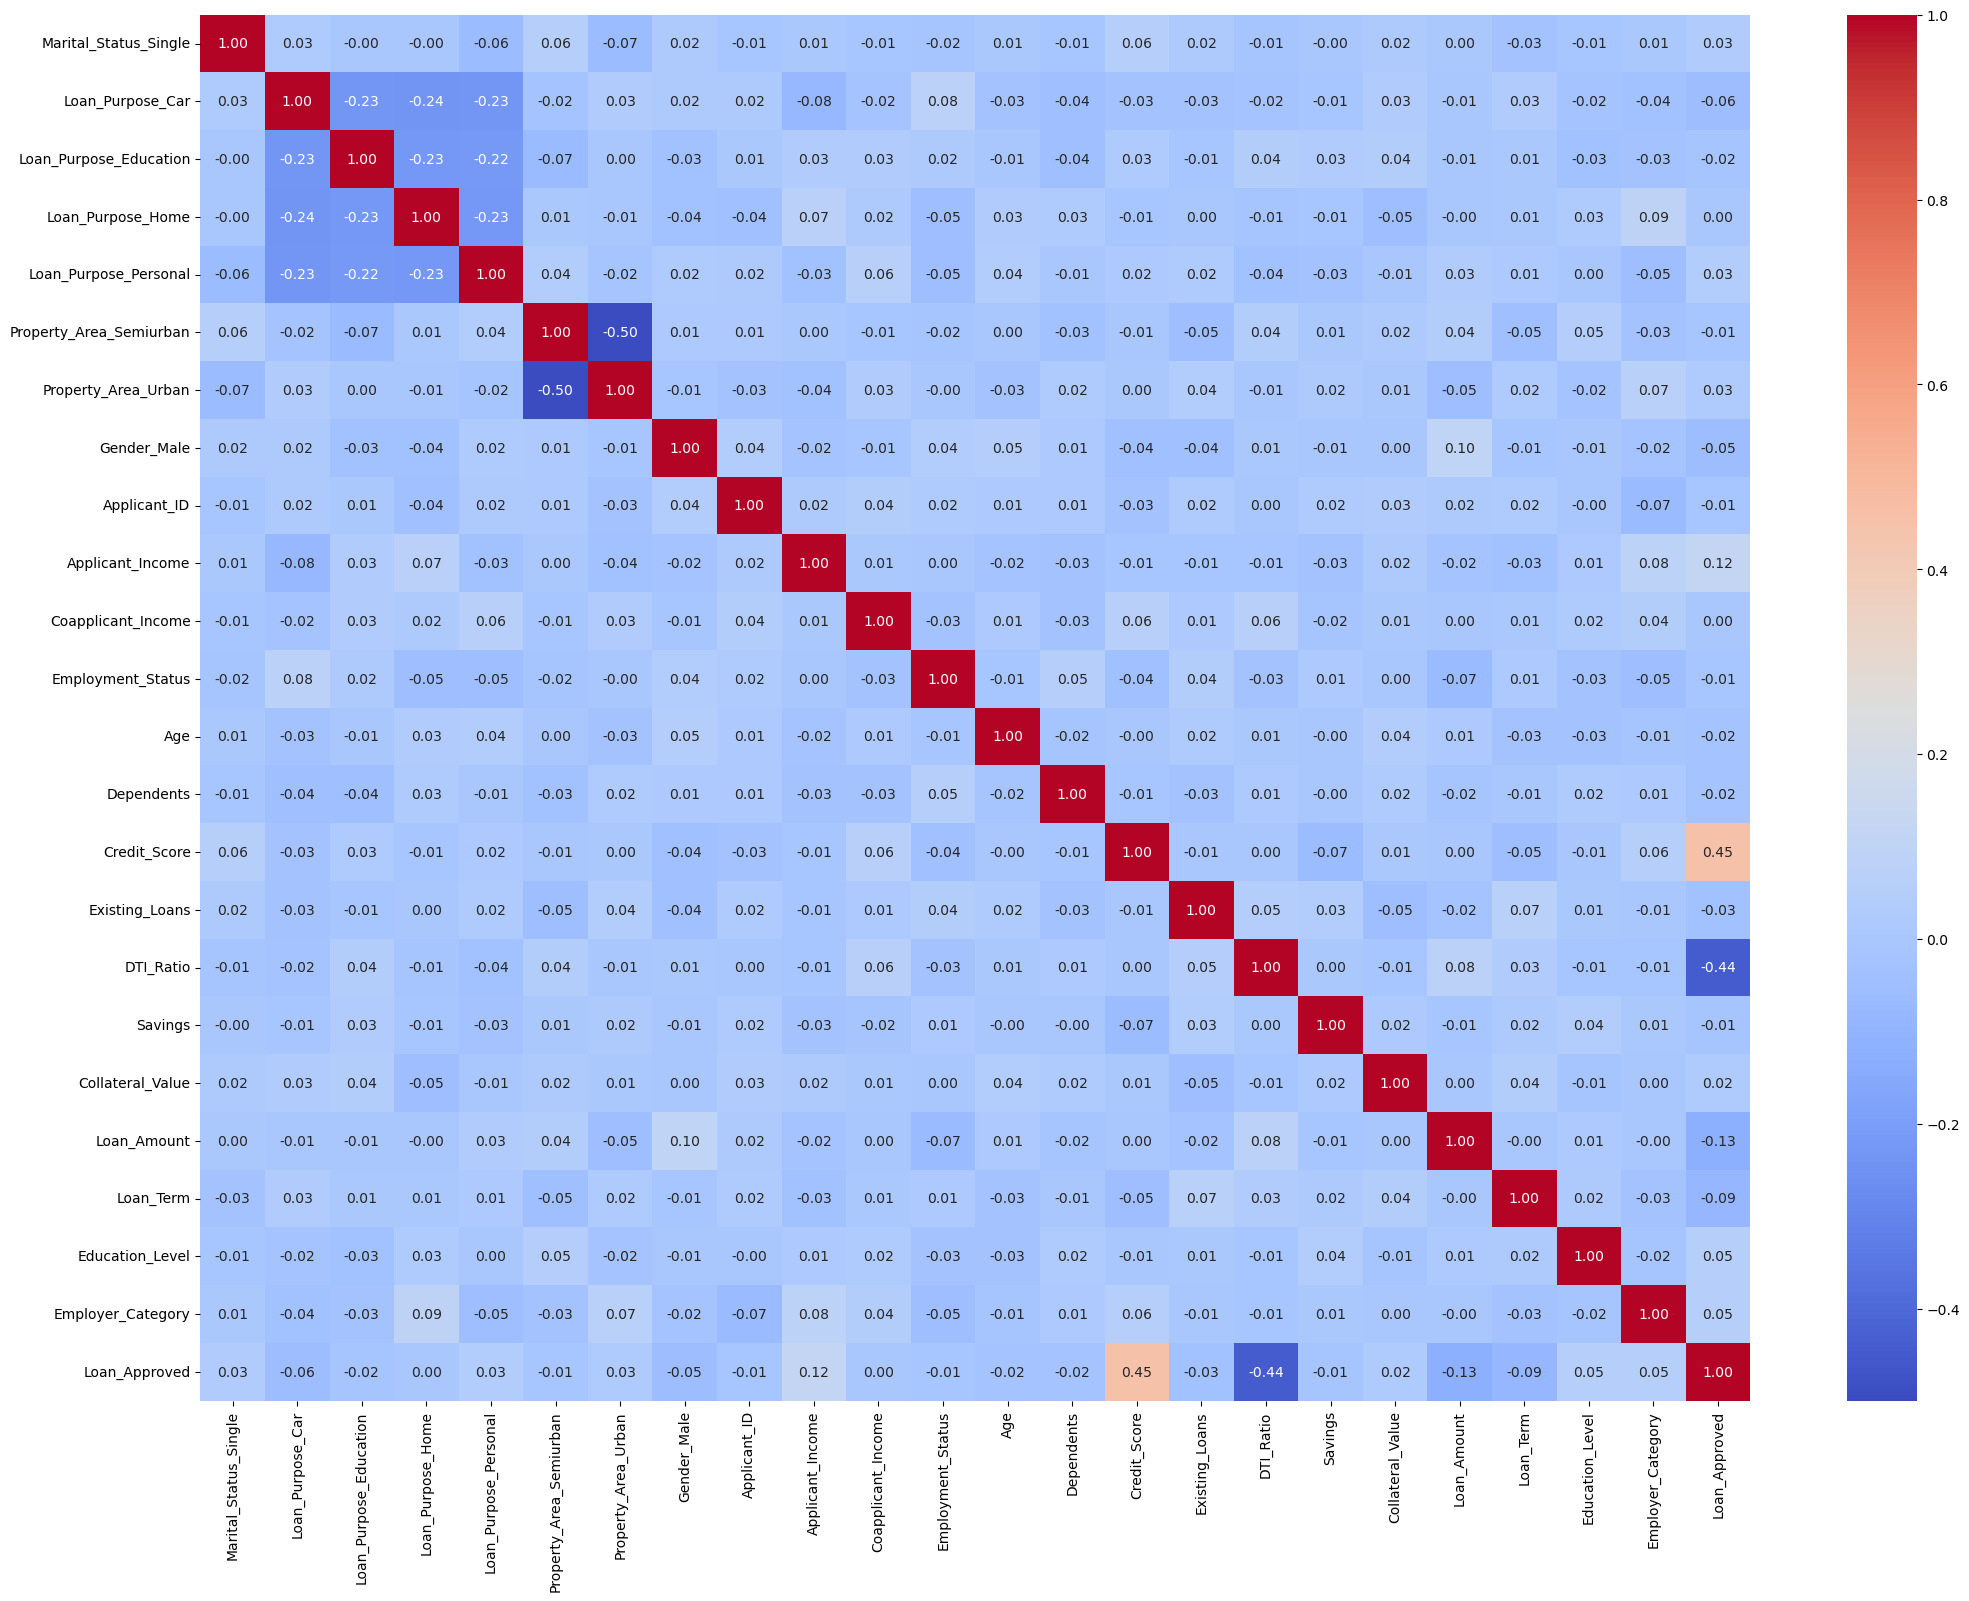

In [142]:
import seaborn as sns

plt.figure(figsize=(25,18))
sns.heatmap(
    df.corr(),
    annot=True,
    fmt = '.2f',
    cmap='coolwarm'
)

### Scaling, Training, Validating, Testing & Evaluating the model

In [143]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

scaler = StandardScaler()

x = df.drop(columns='Loan_Approved')
y = df['Loan_Approved']

X_train,X_test,Y_train,Y_test = train_test_split(x,y,test_size=0.2,random_state=43)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


#### 1. Logistic Regression

In [144]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train_scaled,Y_train)
y_pred = lr.predict(X_test_scaled)


print( "precision_score :",precision_score(Y_test,y_pred))
print("recall_score :",recall_score(Y_test,y_pred))
print("f1_score :",f1_score(Y_test,y_pred))
print("accuracy_score :",accuracy_score(Y_test,y_pred))


precision_score : 0.7142857142857143
recall_score : 0.7142857142857143
f1_score : 0.7142857142857143
accuracy_score : 0.84


#### 2. K Nearest Neighbours Regression

##### 2.1 Hyperparemeter Tuning using GridSearchCV

In [145]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier


knn = GridSearchCV( estimator=KNeighborsClassifier(),param_grid= {"n_neighbors": np.arange(3,30,2)},cv=10 )

In [146]:
knn.fit(X_train_scaled,Y_train)
y_pred = knn.predict(X_test_scaled)

print( "precision_score :",precision_score(Y_test,y_pred))
print("recall_score :",recall_score(Y_test,y_pred))
print("f1_score :",f1_score(Y_test,y_pred))
print("accuracy_score :",accuracy_score(Y_test,y_pred))

print("best parameter: ",knn.best_params_)

precision_score : 0.6666666666666666
recall_score : 0.35714285714285715
f1_score : 0.46511627906976744
accuracy_score : 0.77
best parameter:  {'n_neighbors': np.int64(21)}


#### 3. Naive Bayes

In [147]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train_scaled,Y_train)
y_pred = nb.predict(X_test_scaled)

print( "precision_score :",precision_score(Y_test,y_pred))
print("recall_score :",recall_score(Y_test,y_pred))
print("f1_score :",f1_score(Y_test,y_pred))
print("accuracy_score :",accuracy_score(Y_test,y_pred))


precision_score : 0.7959183673469388
recall_score : 0.6964285714285714
f1_score : 0.7428571428571429
accuracy_score : 0.865


### Feature Engineering

<Axes: ylabel='Frequency'>

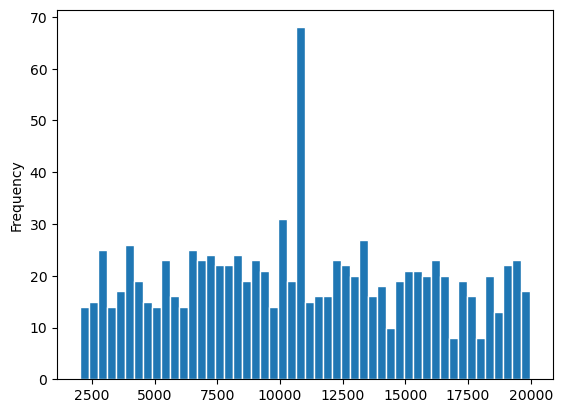

In [148]:
df['Applicant_Income'].sort_values(ascending=False).plot(kind='hist',bins=50,edgecolor="white")

In [149]:
# in the corr heatmap, two of the features were stood up correlated 1)credit score and dti-ratio, and the salaries of applicant and co-applicant are skewed.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Marital_Status_Single    1000 non-null   float64
 1   Loan_Purpose_Car         1000 non-null   float64
 2   Loan_Purpose_Education   1000 non-null   float64
 3   Loan_Purpose_Home        1000 non-null   float64
 4   Loan_Purpose_Personal    1000 non-null   float64
 5   Property_Area_Semiurban  1000 non-null   float64
 6   Property_Area_Urban      1000 non-null   float64
 7   Gender_Male              1000 non-null   float64
 8   Applicant_ID             1000 non-null   float64
 9   Applicant_Income         1000 non-null   float64
 10  Coapplicant_Income       1000 non-null   float64
 11  Employment_Status        1000 non-null   int64  
 12  Age                      1000 non-null   float64
 13  Dependents               1000 non-null   float64
 14  Credit_Score             

In [150]:
df['DTI_Ratio'] = df['DTI_Ratio'] **2
df['Credit_Score'] = df['Credit_Score'] **2
df['Applicant_Income'] = np.log1p(df['Applicant_Income'])
df['Coapplicant_Income'] = np.log1p(df['Coapplicant_Income'])

### After Feature Engineering.

In [151]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

scaler = StandardScaler()

x = df.drop(columns='Loan_Approved')
y = df['Loan_Approved']

X_train,X_test,Y_train,Y_test = train_test_split(x,y,test_size=0.2,random_state=43)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [152]:
print("============= Logistic Regression =============")
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train_scaled,Y_train)
y_pred = lr.predict(X_test_scaled)


print( "precision_score :",precision_score(Y_test,y_pred))
print("recall_score :",recall_score(Y_test,y_pred))
print("f1_score :",f1_score(Y_test,y_pred))
print("accuracy_score :",accuracy_score(Y_test,y_pred))

============= Logistic Regression =============
precision_score : 0.7333333333333333
recall_score : 0.7857142857142857
f1_score : 0.7586206896551724
accuracy_score : 0.86


In [153]:
print("============= KNN =============")
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
knn = GridSearchCV( estimator=KNeighborsClassifier(),param_grid= {"n_neighbors": np.arange(3,30,2)},cv=10 )
knn.fit(X_train_scaled,Y_train)
y_pred = knn.predict(X_test_scaled)

print( "precision_score :",precision_score(Y_test,y_pred))
print("recall_score :",recall_score(Y_test,y_pred))
print("f1_score :",f1_score(Y_test,y_pred))
print("accuracy_score :",accuracy_score(Y_test,y_pred))

print("best parameter: ",knn.best_params_)

============= KNN =============
precision_score : 0.7419354838709677
recall_score : 0.4107142857142857
f1_score : 0.5287356321839081
accuracy_score : 0.795
best parameter:  {'n_neighbors': np.int64(29)}


In [154]:
print("============= Naive Bayes =============")
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train_scaled,Y_train)
y_pred = nb.predict(X_test_scaled)

print( "precision_score :",precision_score(Y_test,y_pred))
print("recall_score :",recall_score(Y_test,y_pred))
print("f1_score :",f1_score(Y_test,y_pred))
print("accuracy_score :",accuracy_score(Y_test,y_pred))


============= Naive Bayes =============
precision_score : 0.8076923076923077
recall_score : 0.75
f1_score : 0.7777777777777778
accuracy_score : 0.88
